#Binary Distillation

**References: Seader et al., 2016**

Distillation is a process that separates a mixture into a distillate and a bottom product based on differences in volatility (Seader et al., 2016).

**Exercise 7.13: Separation of Benzene and Toluene (Seader et al., 2016)**

At an operating pressure of 101 kPa, a distillation column is used to separate 30 kg/h of a bubble-point benzene-toluene mixture containing 60 wt% toluene.

The separation is required to produce a distillate stream containing 97 wt% benzene and a bottoms stream containing 98 wt% toluene.

The column operates at a reflux ratio of 3.5, with the feed introduced at the optimum feed tray and the reflux returned as a saturated liquid. Using the provided vapor-liquid equilibrium (VLE) data:

**Table 1 Vapor-Liquid Equilibrium (VLE) Data for the Benzene-Toluene System at 101 kPa (Mole Fraction of Benzene)**

<table border="1" style="padding:20px;">
  <tr>
    <th>x</th>
    <th>y</th>
  </tr>
  <tr>
    <th>0.1</th>
    <th>0.21</th>
  </tr>
  <tr>
    <th>0.2</th>
    <th>0.37</th>
  </tr>
  <tr>
    <th>0.3</th>
    <th>0.51</th>
  </tr>
  <tr>
    <th>0.4</th>
    <th>0.64</th>
  </tr>
  <tr>
    <th>0.5</th>
    <th>0.72</th>
  </tr>
  <tr>
    <th>0.6</th>
    <th>0.79</th>
  </tr>
   <tr>
    <th>0.7</th>
    <th>0.86</th>
  </tr>
   <tr>
    <th>0.8</th>
    <th>0.91</th>
  </tr>
   <tr>
    <th>0.9</th>
    <th>0.96</th>
  </tr>
  <tr>
    <th>0.95</th>
    <th>0.98</th>
  </tr>
</table>

#Step 1: Define Binary Distillation Variables

Task:
- Define the variables used in the binary distillation process.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Define complement fraction function
def complement_fraction(x):
  return 1-x

benzene_molecular_weight = 78.11
toluene_molecular_weight = 92.14
w_toluene_feed = 0.6
w_benzene_feed = complement_fraction(x=w_toluene_feed)
w_benzene_distillate = 0.97
w_toluene_distillate = complement_fraction(x=w_benzene_distillate)
w_toluene_bottoms = 0.98
w_benzene_bottoms = complement_fraction(x=w_toluene_bottoms)

#Define mass to mole function
def mass_to_mole_fraction(mass_fractions, molecular_weights):
    moles = mass_fractions / molecular_weights
    return moles / np.sum(moles)

feed_mass_fractions = np.array([w_benzene_feed, w_toluene_feed])
distillate_mass_fractions = np.array([w_benzene_distillate, w_toluene_distillate])
bottoms_mass_fractions = np.array([w_benzene_bottoms, w_toluene_bottoms])

#Calculate the mole fractions
component_mws = np.array([benzene_molecular_weight, toluene_molecular_weight])

#Define the vapor-liquid equilibrium data
mole_x_benzene = np.array([0,0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95,1])
mole_y_benzene = np.array([0,0.21,0.37,0.51,0.64,0.72,0.79,0.86,0.91,0.96,0.98,1])

#Define Operating Condition
feed_flow = 30
reflux_ratio = 3.5

#Calculate Mole Fractions
feed_mole_fractions = mass_to_mole_fraction(feed_mass_fractions, component_mws)
distillate_mole_fractions = mass_to_mole_fraction(distillate_mass_fractions, component_mws)
bottoms_mole_fractions = mass_to_mole_fraction(bottoms_mass_fractions, component_mws)
mole_fraction_benzene_feed = feed_mole_fractions[0]
mole_fraction_toluene_feed = feed_mole_fractions[1]

print(f"Feed Mole Fraction (Benzene): {mole_fraction_benzene_feed:.2f}")
print(f"Feed Mole Fraction (Toluene): {mole_fraction_toluene_feed:.2f}")
print(f"Distillate Mole Fraction (Benzene): {distillate_mole_fractions[0]:.2f}")
print(f"Distillate Mole Fraction (Toluene): {distillate_mole_fractions[1]:.2f}")
print(f"Bottoms Mole Fraction (Benzene): {bottoms_mole_fractions[0]:.2f}")
print(f"Bottoms Mole Fraction (Toluene): {bottoms_mole_fractions[1]:.2f}")
print(f"Reflux Ratio: {reflux_ratio:.2f}")



Feed Mole Fraction (Benzene): 0.44
Feed Mole Fraction (Toluene): 0.56
Distillate Mole Fraction (Benzene): 0.97
Distillate Mole Fraction (Toluene): 0.03
Bottoms Mole Fraction (Benzene): 0.02
Bottoms Mole Fraction (Toluene): 0.98
Reflux Ratio: 3.50


#Step 2 : Calculating the distillate and bottoms mass flow rates using mass balance.

Task:
- Determining distillate and bottoms mass flow rates.

In this case, a mass balance was used to determine the mass flow rates of the distillate and bottom streams.

<div align ="center">
$\dot{m}_{\text{in}} = \dot{m}_{\text{out}}$

$F = D +B$

$w_{benzene,F}F = w_{benzene,D}D + w_{benzene,B}B$
</div>

Consequently, the mass balance equations are formulated in matrix notation as follows:
<div align="center">
$
\begin{bmatrix}
1&1\\
w_{benzene,D}&w_{benzene,B}
\end{bmatrix}
\begin{bmatrix}
D\\
B
\end{bmatrix}
=
\begin{bmatrix}
F\\
w_{benzene,F}F
\end{bmatrix}
$
</div>

In [2]:
#Developing the Material Balance Model
A = np.array([[1,1],[w_benzene_distillate,w_benzene_bottoms]])
b = np.array([feed_flow,w_benzene_feed*feed_flow])
x = np.linalg.solve(A,b)
distillate_flow = x[0]
bottoms_flow = x[1]
print(f"Distillate Flow Rate: {distillate_flow:.2f} kg/h")
print(f"Bottoms Flow Rate: {bottoms_flow:.2f} kg/h")

Distillate Flow Rate: 12.00 kg/h
Bottoms Flow Rate: 18.00 kg/h


#Step 3: Tabulating the Material Balance Results

Task:
- Tabulating the material balance calculation results for the distillation process.

In [3]:
import pandas as pd

#Defining the variable and results of material balance calculation
stream = ["Feed","Distillate","Bottoms"]
mass_flow_rate = [feed_flow,distillate_flow,bottoms_flow]
mass_fraction_benzene = [feed_mass_fractions[0],distillate_mass_fractions[0],bottoms_mass_fractions[0]]

data = pd.DataFrame({"Stream":stream,"Overall Mass Flow Rate":mass_flow_rate,"Mass Fraction Benzene":mass_fraction_benzene})
data["Mass Fraction Toluene"] = complement_fraction(data["Mass Fraction Benzene"])
data["Mass Flow Benzene"] = data["Overall Mass Flow Rate"] * data["Mass Fraction Benzene"]
data["Mass Flow Toluene"] = data["Overall Mass Flow Rate"] - data["Mass Flow Benzene"]
print(data)

       Stream  Overall Mass Flow Rate  Mass Fraction Benzene  \
0        Feed                    30.0                   0.40   
1  Distillate                    12.0                   0.97   
2     Bottoms                    18.0                   0.02   

   Mass Fraction Toluene  Mass Flow Benzene  Mass Flow Toluene  
0                   0.60              12.00              18.00  
1                   0.03              11.64               0.36  
2                   0.98               0.36              17.64  


#Step 4: Construct the x-y Equilibrium Diagram

Task:
- Visualize the liquid and vapor equilibrium compositions based on the VLE data.

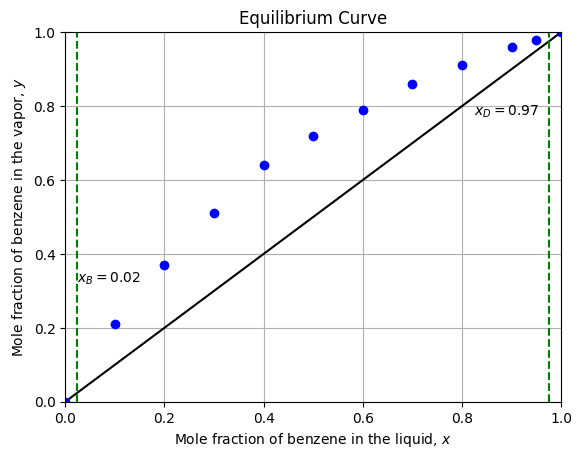

In [4]:
#Define the x–y Line
def line45deg(x):
  return x

increment = 0.1
x_line_45 = np.linspace(0,1,100)
y_line_45 = line45deg(x_line_45)

plt.plot(x_line_45,y_line_45,color="black")
plt.plot(mole_x_benzene,mole_y_benzene,'bo')
plt.title('Equilibrium Curve')
plt.xlabel('Mole fraction of benzene in the liquid, $x$')
plt.ylabel('Mole fraction of benzene in the vapor, $y$')
plt.xlim(0,1)
plt.ylim(0,1)
plt.vlines(x=distillate_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.vlines(x=bottoms_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.text(distillate_mole_fractions[0]-0.15,distillate_mole_fractions[0]-0.2,f"$x_D={distillate_mole_fractions[0]:.2f}$")
plt.text(bottoms_mole_fractions[0],bottoms_mole_fractions[0]+0.3,f"$x_B={bottoms_mole_fractions[0]:.2f}$")
plt.grid()
plt.show()

#Step 5: Fitting the equilibrium curve

Task:
- Fitting the Equilibrium Curve Using Vapor-Liquid Equilibrium (VLE) Data

The vapor-liquid equilibrium equation describing the relationship between liquid-phase composition ($x$) and vapor-phase composition ($y$) is given as follows.

$$
y = \frac{\alpha_{1,2}x}{1+x(\alpha_{1,2}-1)}
$$

R2 Score: 0.9995


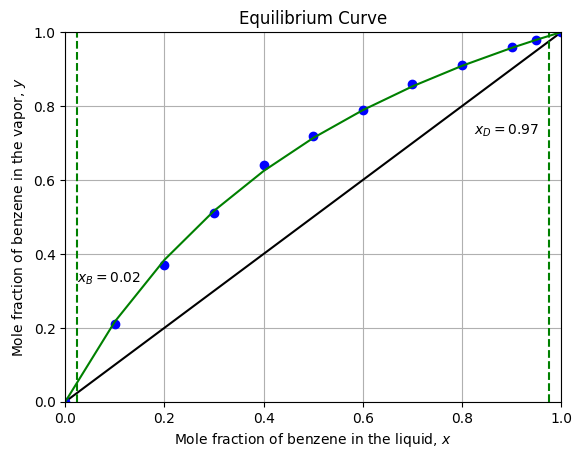

In [5]:
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

#Define the Equilibrium Relationship as a Function
def y_equilibrium(x,alpha):
  y = alpha*x / (1 + x*(alpha - 1))
  return y

#Perform curve fitting on the VLE data
popt, pcov = curve_fit(y_equilibrium,mole_x_benzene,mole_y_benzene)
alpha = popt[0]
y_benzene_fitted = y_equilibrium(mole_x_benzene,alpha)

#Display R2 score
value_r2_score = r2_score(mole_y_benzene,y_benzene_fitted)
print(f"R2 Score: {value_r2_score:.4f}")

#Visualize the chart
plt.plot(x_line_45,y_line_45,color="black")
plt.plot(mole_x_benzene,mole_y_benzene,'bo',label="Equilibrium Data")
plt.plot(mole_x_benzene,y_benzene_fitted,'g-',label="Fitted Equilibrium Curve")
plt.grid()
plt.title('Equilibrium Curve')
plt.xlabel('Mole fraction of benzene in the liquid, $x$')
plt.ylabel('Mole fraction of benzene in the vapor, $y$')
plt.xlim(0,1)
plt.ylim(0,1)
plt.vlines(x=distillate_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.vlines(x=bottoms_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.text(distillate_mole_fractions[0]-0.15,distillate_mole_fractions[0]-0.25,f"$x_D={distillate_mole_fractions[0]:.2f}$")
plt.text(bottoms_mole_fractions[0],bottoms_mole_fractions[0]+0.3,f"$x_B={bottoms_mole_fractions[0]:.2f}$")
plt.show()

# Step 6: Development of the Operating Lines for the Rectifying, Stripping, and Feed Sections

Task:
- Determine the operating line for the rectifying section.
- Determine the operating line for the stripping section.
- Determine the feed $q$-line.

The operating line in the rectifying section can be expressed by the following equation.

$$
y = \frac{R}{R+1}x + \frac{1}{R+1}x_{d}
$$

Subsequently, the feed line is described by the following equation.
$$
y = \frac{q}{q-1}x - \frac{z_F}{q-1}
$$

Finally, the operating line in the stripping section can be determined by the following equation

$$
y = \frac {V_B + 1}{V_B}x - \frac{1}{V_B}x_B
$$

Where:
- $R$ = Reflux ratio
- $z_F$ = Feed composition (mole fraction of the feed).
- $q$ = Feed thermal condition parameter, representing the fraction of the feed entering the column as liquid.
- $V_B$ = Boilup ratio
- $x_D$ = Mole fraction of the distillate product.
- $x_B$ = Mole fraction of the bottoms product.

Note:
- Feed condition parameter ($q$):
  <table border="1" style="border-collapse: collapse;">
    <tr>
      <th>q-value</th>
      <th>Feed Condition</th>
    </tr>
    <tr>
      <td> q < 0 </td>
      <td>Superheated Vapor</td>
    </tr>
    <tr>
      <td> q = 0 </td>
      <td>Dew-point Vapor</td>
    </tr>
    <tr>
      <td>0 &lt; q &lt; 1</td>
      <td >Partially Vaporized</td>
    </tr>
    <tr>
      <td>q = 1</td>
      <td>Bubble-point Liquid</td>
    </tr>
      <td>q > 1</td>
      <td>Subcooled Liquid</td>
    </tr>
  </table>

- In this case, the feed is at its bubble point, so the q-value is equal to 1. Therefore, the q-line is represented by:
<p align="center">
      $x = z_F$
</p>

- The stripping operating line is drawn from $(x_B,y_B)$ to the intersection of the q-line and the rectifying operating line.


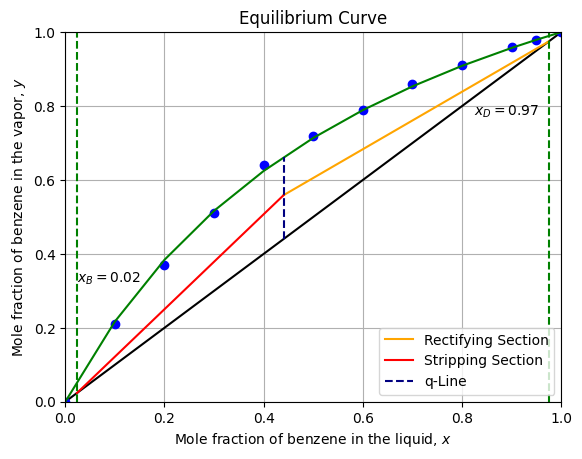

In [6]:
#Defining the Operating Line Function for the Rectifying Section
def rectifying_section_line(x):
  y = (reflux_ratio/(reflux_ratio+1))*x + (1/(reflux_ratio+1))*distillate_mole_fractions[0]
  return y

#Calculate the Operating Line for the Rectifying Section
x_rectifying_line = np.linspace(mole_fraction_benzene_feed,distillate_mole_fractions[0],10)
y_rectifying_line = rectifying_section_line(x_rectifying_line)

#Calculate the Operating Line for the Stripping Section
y_feed_mole_benzene = rectifying_section_line(mole_fraction_benzene_feed)

def stripping_section_line(x):
  return (x - bottoms_mole_fractions[0])*(y_feed_mole_benzene - bottoms_mole_fractions[0])/(mole_fraction_benzene_feed - bottoms_mole_fractions[0]) + bottoms_mole_fractions[0]

x_stripping_benzene = np.linspace(bottoms_mole_fractions[0],mole_fraction_benzene_feed,100)
y_stripping_benzene = stripping_section_line(x_stripping_benzene)


#Plotting the equilibrium curve and the 45-degree diagonal line
plt.plot(x_line_45,y_line_45,color="black")
plt.plot(mole_x_benzene,mole_y_benzene,'bo')

#Plotting the fitted curve
plt.plot(mole_x_benzene,y_benzene_fitted,'g-')

#Plotting the Rectifying Operating Line
plt.plot(x_rectifying_line,y_rectifying_line,'orange',label="Rectifying Section")

#Plotting the Stripping Feed Line
plt.plot(x_stripping_benzene,y_stripping_benzene,'red',label="Stripping Section")

#Plotting the Feed Line
plt.vlines(x=mole_fraction_benzene_feed,ymin=mole_fraction_benzene_feed,ymax=y_equilibrium(mole_fraction_benzene_feed,alpha),color="navy",ls='--',label="q-Line")

#Visualizing the chart
plt.grid()
plt.title('Equilibrium Curve')
plt.xlabel('Mole fraction of benzene in the liquid, $x$')
plt.ylabel('Mole fraction of benzene in the vapor, $y$')
plt.xlim(0,1)
plt.ylim(0,1)
plt.vlines(x=distillate_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.vlines(x=bottoms_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.text(distillate_mole_fractions[0]-0.15,distillate_mole_fractions[0]-0.2,f"$x_D={distillate_mole_fractions[0]:.2f}$")
plt.text(bottoms_mole_fractions[0],bottoms_mole_fractions[0]+0.3,f"$x_B={bottoms_mole_fractions[0]:.2f}$")
plt.legend(loc="lower right")
plt.show()

#Step 5 : Determining the Feed Stage and Number of Distillation Stages Using the McCabe-Thiele Method

Task:
- Determining the Number of Theoretical Stages in the Distillation Column
- Identifying the Feed Stage Location

To determine the horizontal lines in the McCabe-Thiele method, the liquid mole fraction ($x$) must be represented as a function of the vapor mole fraction ($y$). Based on the vapor-liquid equilibrium relationship, the following equation is obtained:

$$
y = \frac{\alpha_{1,2}x}{1+x(\alpha_{1,2}-1)}
$$

So,

$$
x = \frac{y}{\alpha_{1,2}(1-y)+y}
$$



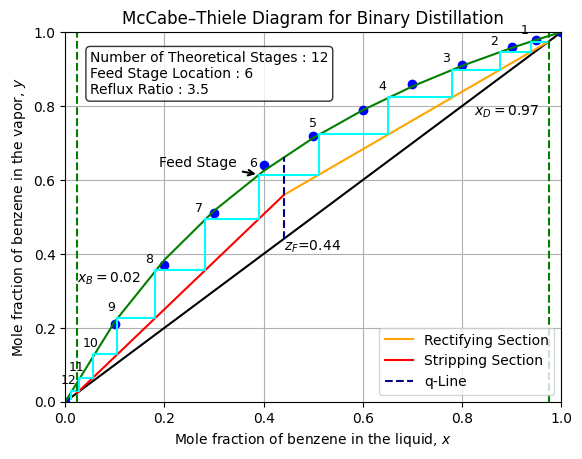

Number of Theoritical Stage : 12
Number of Stages in Rectifying Section : 5
Number of Stages in Stripping Section : 6
Feed Stage Location : Stage 6


In [7]:
#Defining x as a function of y
def x_equilibrium(y):
  x = y / (alpha*(1-y)+y)
  return x

#Determining Number of Stages in the Distillation Column
number_of_stages =  [0, 0, 0]
initial_value = np.array([distillate_mole_fractions[0],distillate_mole_fractions[0]])
stage_line = np.array(initial_value)
horizontal_point = np.empty((0,2))
while initial_value[0] > bottoms_mole_fractions[0]:
    x_horizontal = x_equilibrium(initial_value[1])
    y_horizontal = initial_value[1]
    horizontal_point = np.vstack((horizontal_point,np.array([x_horizontal,y_horizontal])))
    number_of_stages[0] += 1
    if x_horizontal > mole_fraction_benzene_feed:
      x_vertical = x_horizontal
      y_vertical = rectifying_section_line(x_horizontal)
      stage_line = np.vstack((stage_line,np.array([x_horizontal,y_horizontal]),np.array([x_vertical,y_vertical])))
      initial_value = stage_line[-1]
      number_of_stages[1] += 1
    else:
      x_vertical = x_horizontal
      y_vertical = stripping_section_line(x_horizontal)
      stage_line = np.vstack((stage_line,np.array([x_horizontal,y_horizontal]),np.array([x_vertical,y_vertical])))
      initial_value = stage_line[-1]
      number_of_stages[2] += 1

feed_stage = number_of_stages[2] - 1
stripping_stage = number_of_stages[2] - 1
rectifying_stage = number_of_stages[1]

#Plot the equilibrium curve and the 45-degree diagonal line
plt.plot(x_line_45,y_line_45,color="black")
plt.plot(mole_x_benzene,mole_y_benzene,'bo')

#Plotting the fitted curve
plt.plot(mole_x_benzene,y_benzene_fitted,'g-')

#Plotting the Rectifying Operating Line
plt.plot(x_rectifying_line,y_rectifying_line,'orange',label="Rectifying Section")

#Plotting the Stripping Feed Line
plt.plot(x_stripping_benzene,y_stripping_benzene,'red',label="Stripping Section")

#Plotting the Feed Line
plt.vlines(x=mole_fraction_benzene_feed,ymin=mole_fraction_benzene_feed,ymax=y_equilibrium(mole_fraction_benzene_feed,alpha),color="navy",ls='--',label="q-Line")

#Plotting the Stage
plt.plot(stage_line[:,0],stage_line[:,1],'cyan')
for i, (x, y) in enumerate(horizontal_point, start=1):
    plt.text(
        x-0.02,
        y+0.02,
        f'{i}',
        fontsize=9,
        color='black'
    )

#Visualizing the chart
plt.title("McCabe–Thiele Diagram for Binary Distillation")
plt.xlabel('Mole fraction of benzene in the liquid, $x$')
plt.ylabel('Mole fraction of benzene in the vapor, $y$')
plt.xlim(0,1)
plt.ylim(0,1)
plt.vlines(x=distillate_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.vlines(x=bottoms_mole_fractions[0],ymin=0,ymax=1,color="green",ls='--')
plt.text(distillate_mole_fractions[0]-0.15,distillate_mole_fractions[0]-0.2,f"$x_D={distillate_mole_fractions[0]:.2f}$")
plt.text(bottoms_mole_fractions[0],bottoms_mole_fractions[0]+0.3,f"$x_B={bottoms_mole_fractions[0]:.2f}$")
plt.text(mole_fraction_benzene_feed,mole_fraction_benzene_feed-0.03,f"$z_F$={mole_fraction_benzene_feed:.2F}")

#Highlight the feed stage using an arrow
plt.annotate(
    "Feed Stage",
    xy=(horizontal_point[feed_stage-1][0], horizontal_point[feed_stage-1][1]),
    xytext=(horizontal_point[feed_stage-1][0]-0.2,
            horizontal_point[feed_stage-1][1]+0.02),
    arrowprops=dict(
        arrowstyle="->",
        color="black",
        lw=1.5
    ),
    fontsize=10,
    color="black"
)

#Display a text box on the chart
text_box = (
    f"Number of Theoretical Stages : {number_of_stages[0]}\n"
    f"Feed Stage Location : {number_of_stages[2]-1}\n"
    f"Reflux Ratio : {reflux_ratio}"
)
plt.text(0.05,0.95,text_box,transform=plt.gca().transAxes,fontsize=10,verticalalignment='top',bbox=dict(boxstyle='round',facecolor='white',edgecolor='black',alpha=0.8))
plt.legend(loc="lower right")
plt.grid()
plt.show()
print(f"Number of Theoritical Stage : {number_of_stages[0]}")
print(f"Number of Stages in Rectifying Section : {number_of_stages[1]}")
print(f"Number of Stages in Stripping Section : {number_of_stages[2]-1}")
print(f"Feed Stage Location : Stage {number_of_stages[2]-1}")

#References:
- McCabe, W. L., & Thiele, E. W. (1925). Graphical design of fractionating columns. Industrial & Engineering Chemistry, 17(6), 605–611. https://doi.org/10.1021/ie50186a023
- Seader, J. D., Henley, E. J., & Roper, D. K. (2016). Separation process principles with applications using process simulators (4th ed.). John Wiley & Sons, Inc.